# 02 - Duplicate audit (Week 3)

**Why this matters:** if a Testing image has a copy (or near copy) in Training, the model has effectively *seen the answer*. Test accuracy then measures memory, not generalisation, a form of **data leakage**.

**Two checks per dataset version** (on the original files in `./data/`, read-only):
- **MD5** - a fingerprint of the file bytes. Equal MD5 = byte-for-byte identical file (*exact copy*).
- **pHash** (perceptual hash, 64 bits) - shrink the image to 32x32 grey, take the DCT (frequency transform), keep the 8x8 lowest frequencies and set each bit to 1 if above the median. Similar-looking images get similar bits, even after re-saving, resizing or small brightness changes.
- **Hamming distance** = number of differing bits between two pHashes (0 = same hash, 64 = opposite). Pairs with distance <= T are *near copies*. We compare T = 3, 5 and 8.

All pairwise distances are computed on the GPU as one matrix product per block of rows (`hamming = ones(a) + ones(b) - 2 a.b`). Code: `src/audit.py`.

In [1]:
import os, sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import torch
from IPython.display import Image as ShowImage, display
from src import audit as a
from src import data as d

d.set_seed(d.SEED)
VERSIONS = ['v1', 'v2']
OUT = {v: Path('outputs/audit') / v for v in VERSIONS}
for p in OUT.values():
    p.mkdir(parents=True, exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU fallback)')

D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce GTX 1650 Ti


## 1. Hash every image (MD5 + pHash)

In [2]:
hashes = {}
for v in VERSIONS:
    hashes[v] = a.hash_images(f'outputs/splits/{v}_original.csv')
    hashes[v].to_csv(OUT[v] / 'hashes.csv', index=False)
pd.DataFrame([{'version': v, 'images': len(h), 'distinct_md5': h['md5'].nunique(),
               'distinct_phash': h['phash'].nunique()} for v, h in hashes.items()])

Hashing:   0%|          | 0/7023 [00:00<?, ?it/s]

Hashing:   0%|          | 1/7023 [00:01<2:18:05,  1.18s/it]

Hashing:   0%|          | 10/7023 [00:01<11:17, 10.35it/s] 

Hashing:   0%|          | 33/7023 [00:01<02:57, 39.30it/s]

Hashing:   1%|          | 60/7023 [00:01<01:31, 75.82it/s]

...

Hashing:  99%|█████████▊| 7102/7200 [00:19<00:00, 365.57it/s]

Hashing:  99%|█████████▉| 7140/7200 [00:19<00:00, 341.35it/s]

Hashing: 100%|█████████▉| 7175/7200 [00:19<00:00, 321.40it/s]

Hashing: 100%|██████████| 7200/7200 [00:19<00:00, 364.47it/s]

,version,images,distinct_md5,distinct_phash
0,v1,7023,6726,5910
1,v2,7200,7013,6212


## 2. Pairwise Hamming distances on the GPU
We keep every pair with distance <= 10 so any threshold up to 10 can be studied. The GPU result is checked against imagehash's own distance on 1,000 random pairs.

In [3]:
pairs, timing = {}, []
for v in VERSIONS:
    bits = a.phash_bits(hashes[v]['phash'])
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    start = time.perf_counter()
    i, j, dist = a.pairwise_hamming(bits)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    n = len(bits)
    pairs[v] = a.build_pairs(hashes[v], i, j, dist)
    pairs[v].to_csv(OUT[v] / 'pairs.csv', index=False)
    timing.append({'version': v, 'images': n, 'pairs_compared': n * (n - 1) // 2,
                   'gpu_seconds': round(seconds, 3),
                   'peak_vram_MB': round(torch.cuda.max_memory_allocated() / 1e6, 1) if torch.cuda.is_available() else None,
                   'pairs_kept_(d<=10)': len(pairs[v]),
                   'mismatches_vs_imagehash_(1000)': a.verify_hamming(hashes[v], bits),
                   'exact_pairs': int(pairs[v]['exact'].sum()),
                   'exact_pairs_check_md5_groups': a.exact_pairs_check(hashes[v])})
pd.DataFrame(timing)

,version,images,pairs_compared,gpu_seconds,peak_vram_MB,pairs_kept_(d<=10),mismatches_vs_imagehash_(1000),exact_pairs,exact_pairs_check_md5_groups
0,v1,7023,24657753,3.452,142.5,31366,0,503,503
1,v2,7200,25916400,0.065,142.9,31956,0,227,227


## 3. How the counts change with the threshold (3 / 5 / 8)
*exact_pairs* are always counted. *near_pairs* are extra pairs within the threshold that are not byte-identical. *label_conflicts* = duplicate pairs whose two images have **different** class labels.

In [4]:
summary = pd.concat({v: a.threshold_summary(pairs[v], hashes[v]) for v in VERSIONS}, names=['version'])
for v in VERSIONS:
    summary.loc[v].to_csv(OUT[v] / 'threshold_summary.csv', index=False)
summary.droplevel(1)

,threshold,exact_pairs,near_pairs (not exact),train-train,test-test,train-test,label_conflicts,test_with_train_twin,test_with_train_twin_%
version,,,,,,,,,
v1,3,503,3973,2595,229,1652,2,547,41.72
v1,5,503,6031,3977,280,2277,33,724,55.23
v1,8,503,14654,9961,497,4699,1850,1145,87.34
v2,3,227,3658,2197,308,1380,11,505,31.56
v2,5,227,5666,3450,416,2027,47,714,44.62
v2,8,227,14626,9195,918,4740,1992,1248,78.00


## 4. Testing images that have a twin in Training, per class

In [5]:
twins = {v: a.test_twins_per_class(pairs[v], hashes[v]) for v in VERSIONS}
for v in VERSIONS:
    twins[v].to_csv(OUT[v] / 'test_twins_per_class.csv', index=False)
print('Threshold T = 5:')
pd.concat({v: t[t['threshold'] == 5].drop(columns='threshold').set_index('class') for v, t in twins.items()}, axis=1)

Threshold T = 5:


v1                                  v2                  \
           test_images with_train_twin percent test_images with_train_twin   
class                                                                        
glioma             300              68   22.67         400              86   
meningioma         306             157   51.31         400             173   
notumor            405             385   95.06         400             353   
pituitary          300             114   38.00         400             102   

                    
           percent  
class               
glioma       21.50  
meningioma   43.25  
notumor      88.25  
pituitary    25.50

In [6]:
# Percentage of Testing images with a Training twin, for every threshold.
pd.concat({v: t.pivot(index='class', columns='threshold', values='percent') for v, t in twins.items()},
          axis=1).rename_axis(columns=['version', 'T'])

version        v1                   v2             
T               3      5      8      3      5     8
class                                              
glioma       5.67  22.67  75.33   6.00  21.50  63.5
meningioma  39.54  51.31  85.62  31.00  43.25  78.5
notumor     91.85  95.06  97.78  82.00  88.25  93.5
pituitary   12.33  38.00  87.00   7.25  25.50  76.5

In [7]:
# Duplicate pairs whose labels disagree (T = 5): the same picture filed under two classes.
for v in VERSIONS:
    conf = a.within(pairs[v], 5)
    conf = conf[conf['label_conflict']]
    print(f'{v}: {len(conf)} label-conflict pairs at T=5')
    if len(conf):
        display(conf.groupby(['label_a', 'label_b', 'pair_type']).size().rename('pairs').to_frame())

v1: 33 label-conflict pairs at T=5


pairs
label_a    label_b    pair_type         
glioma     meningioma test-test        1
                      train-train     18
           notumor    test-test        1
                      train-test       2
                      train-train      4
meningioma glioma     train-test       2
           notumor    test-test        1
                      train-test       1
                      train-train      1
notumor    glioma     train-test       1
           meningioma train-test       1

v2: 47 label-conflict pairs at T=5


pairs
label_a    label_b    pair_type         
glioma     meningioma test-test        5
                      train-test       6
                      train-train     20
           notumor    train-train      3
meningioma glioma     train-test       8
           notumor    train-train      1
notumor    glioma     train-test       1
           meningioma train-test       1
pituitary  meningioma train-test       2

## 5. Duplicate groups (for the leakage-free split later)
Images linked by any duplicate pair (T = 5) form one group; all members of a group must go to the same split.

In [8]:
for v in VERSIONS:
    groups = a.duplicate_groups(hashes[v], pairs[v], T=5)
    groups.to_csv(OUT[v] / 'groups_T5.csv', index=False)
    sizes = groups['group_id'].value_counts()
    mixed = groups.groupby('group_id')['split'].nunique().gt(1).sum()
    print(f'{v}: {len(groups):,} images -> {groups.group_id.nunique():,} groups; '
          f'{(sizes > 1).sum():,} groups have 2+ images (largest {sizes.max()}); '
          f'{mixed:,} groups span Training and Testing')

v1: 7,023 images -> 4,516 groups; 1,072 groups have 2+ images (largest 28); 542 groups span Training and Testing
v2: 7,200 images -> 4,755 groups; 1,103 groups have 2+ images (largest 28); 520 groups span Training and Testing


## 6. Distance histogram (train-test pairs)

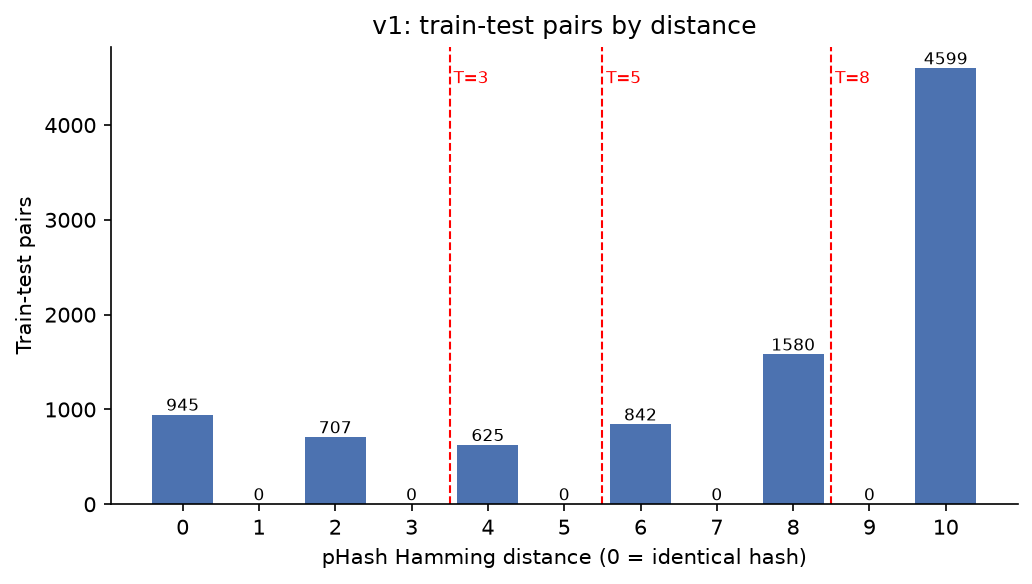

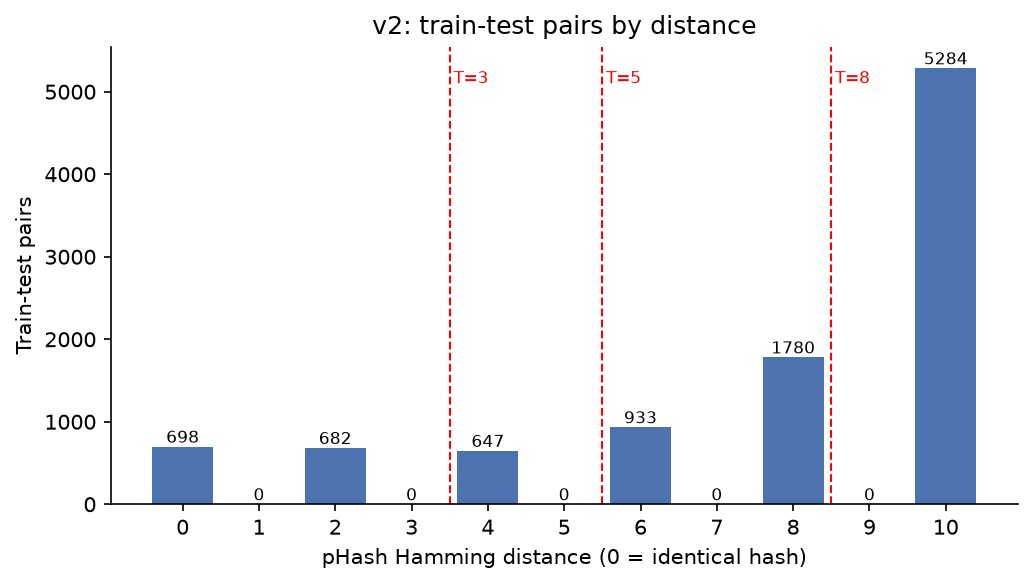

In [9]:
for v in VERSIONS:
    display(ShowImage(filename=str(a.plot_distance_hist(pairs[v], OUT[v], v))))

## 7. Six near-duplicate Training | Testing pairs

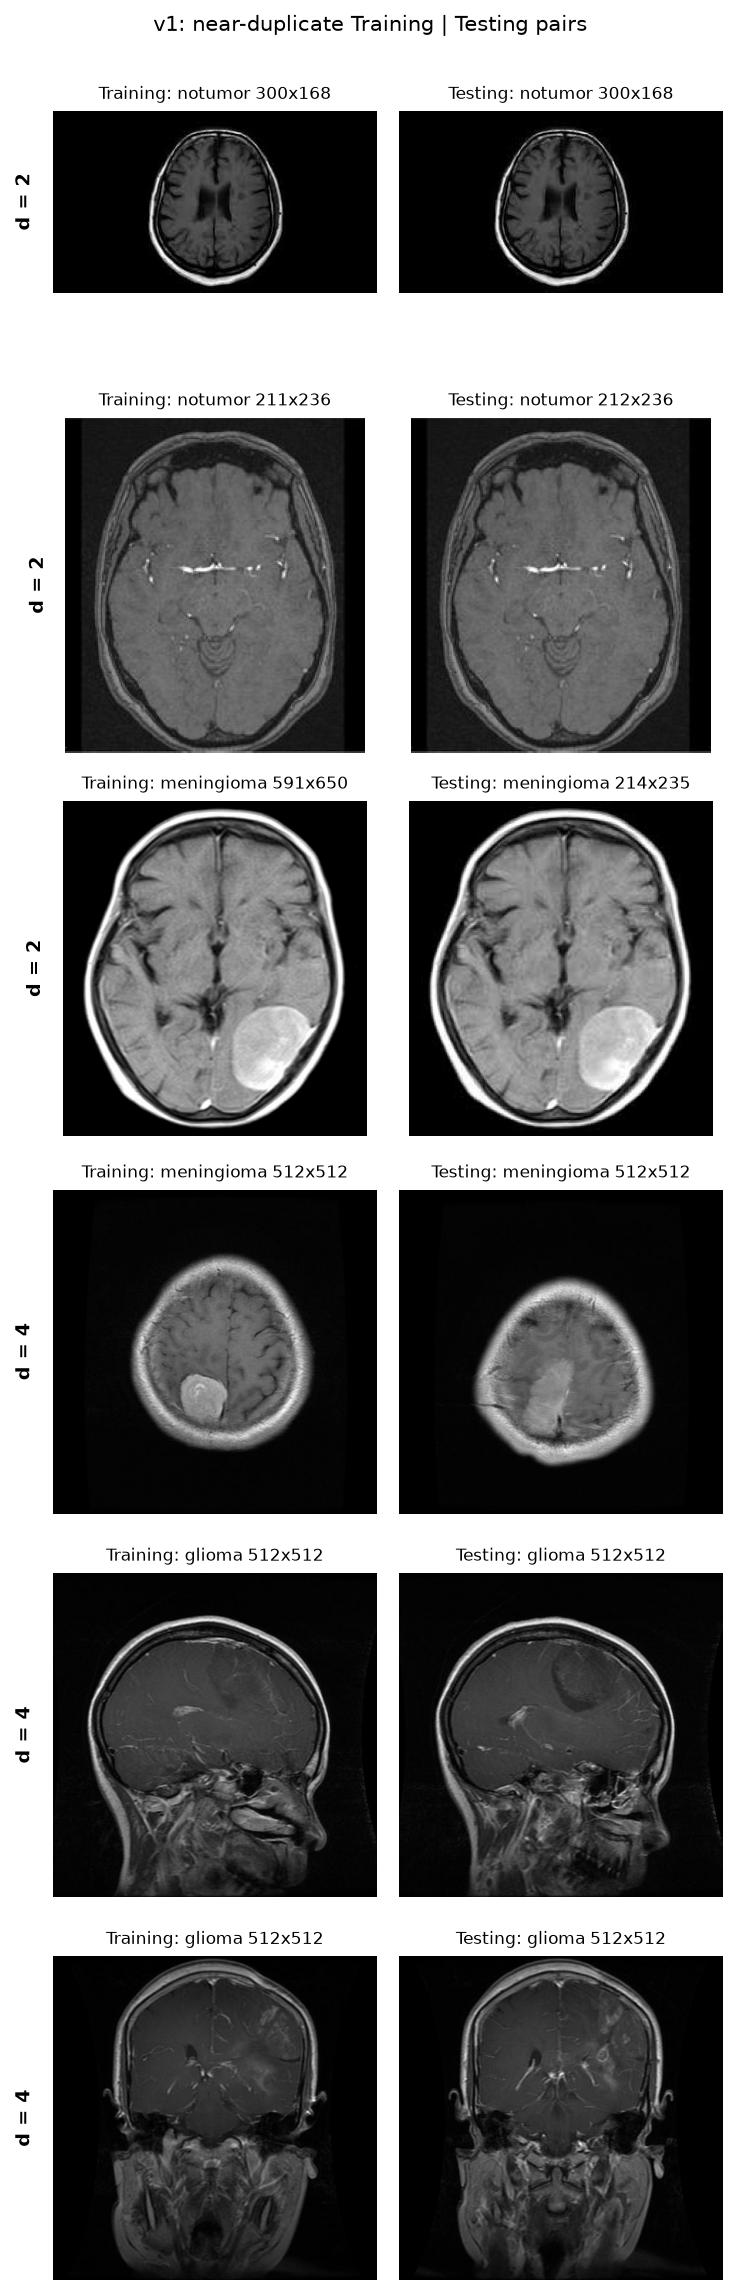

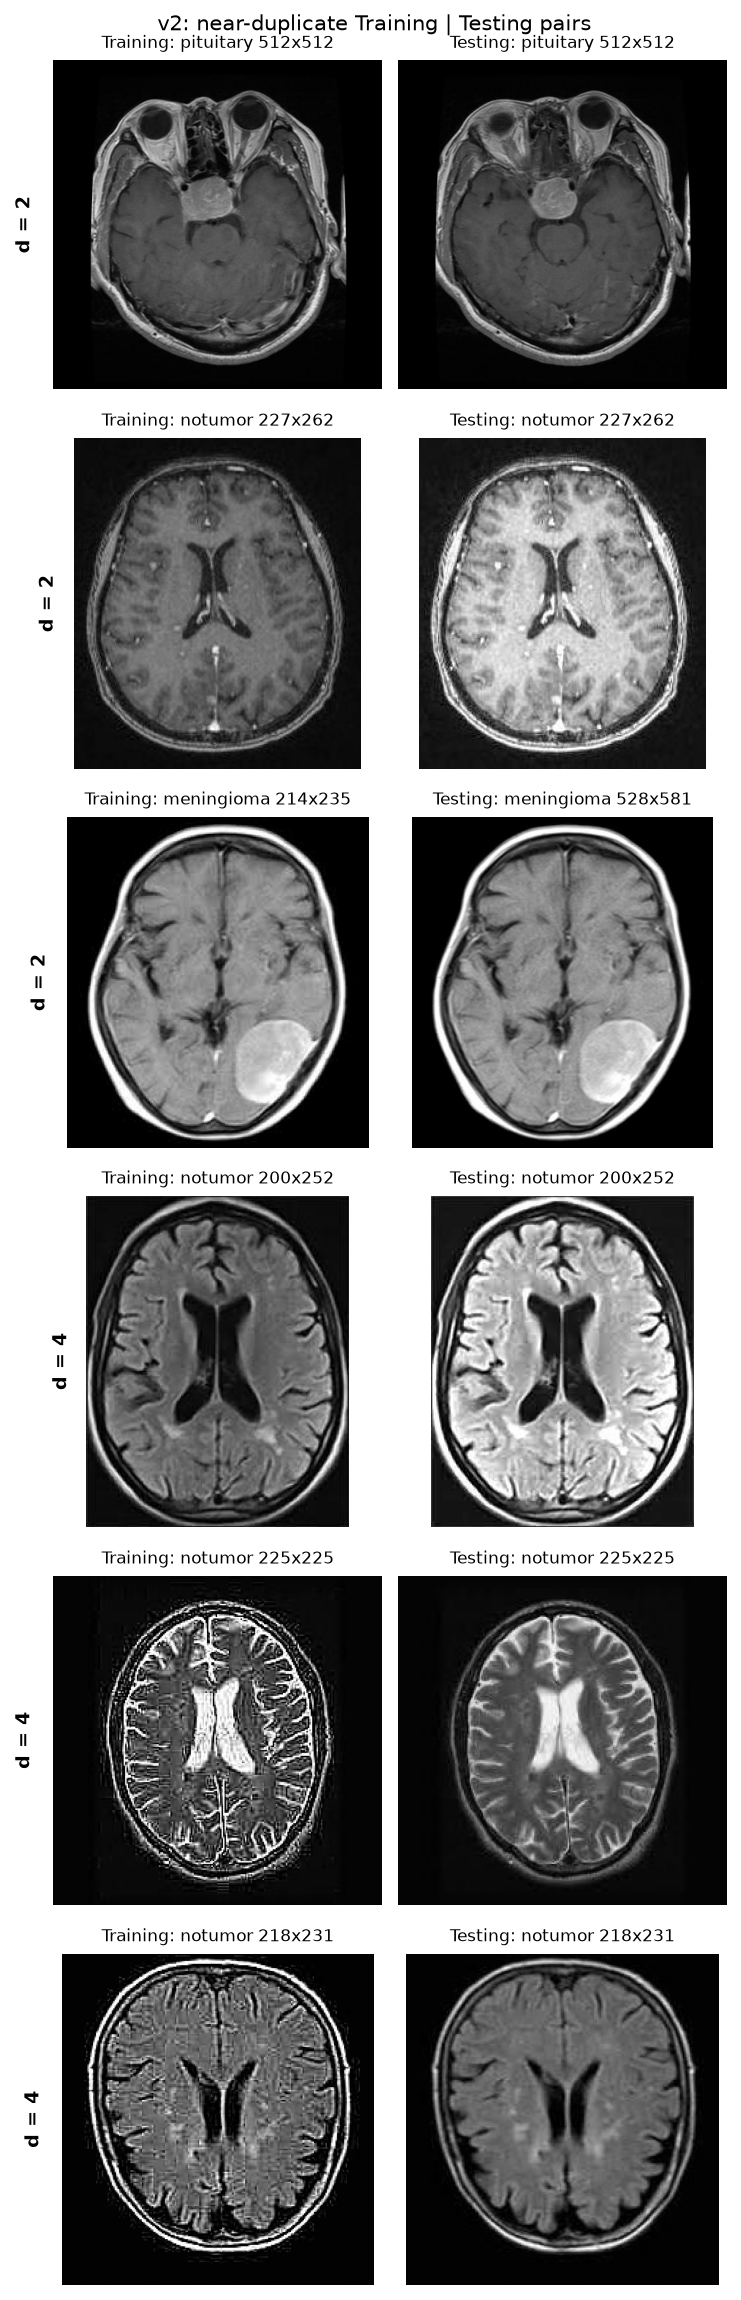

In [10]:
for v in VERSIONS:
    display(ShowImage(filename=str(a.plot_near_dup_examples(pairs[v], OUT[v], v))))

## 8. Pairs at distance 0, 2, 4, 6 and 8 (to judge the threshold by eye)
Only **even** distances occur: every pHash has exactly 32 one-bits (each bit means *above the median*), so bits always change in pairs. That is why T = 3 gives the same result as T = 2, and T = 5 the same as T = 4.

In [11]:
for v in VERSIONS:
    ones = a.phash_bits(hashes[v]['phash']).sum(dim=1)
    print(v, 'one-bits per hash:', pd.Series(ones.numpy()).value_counts().to_dict())
    tt = pairs[v][pairs[v]['pair_type'] == 'train-test']
    print(v, 'train-test pairs by distance:', tt['distance'].value_counts().sort_index().to_dict())

v1 one-bits per hash: {32: 7023}
v1 train-test pairs by distance: {0: 945, 2: 707, 4: 625, 6: 842, 8: 1580, 10: 4599}
v2 one-bits per hash: {32: 7200}
v2 train-test pairs by distance: {0: 698, 2: 682, 4: 647, 6: 933, 8: 1780, 10: 5284}


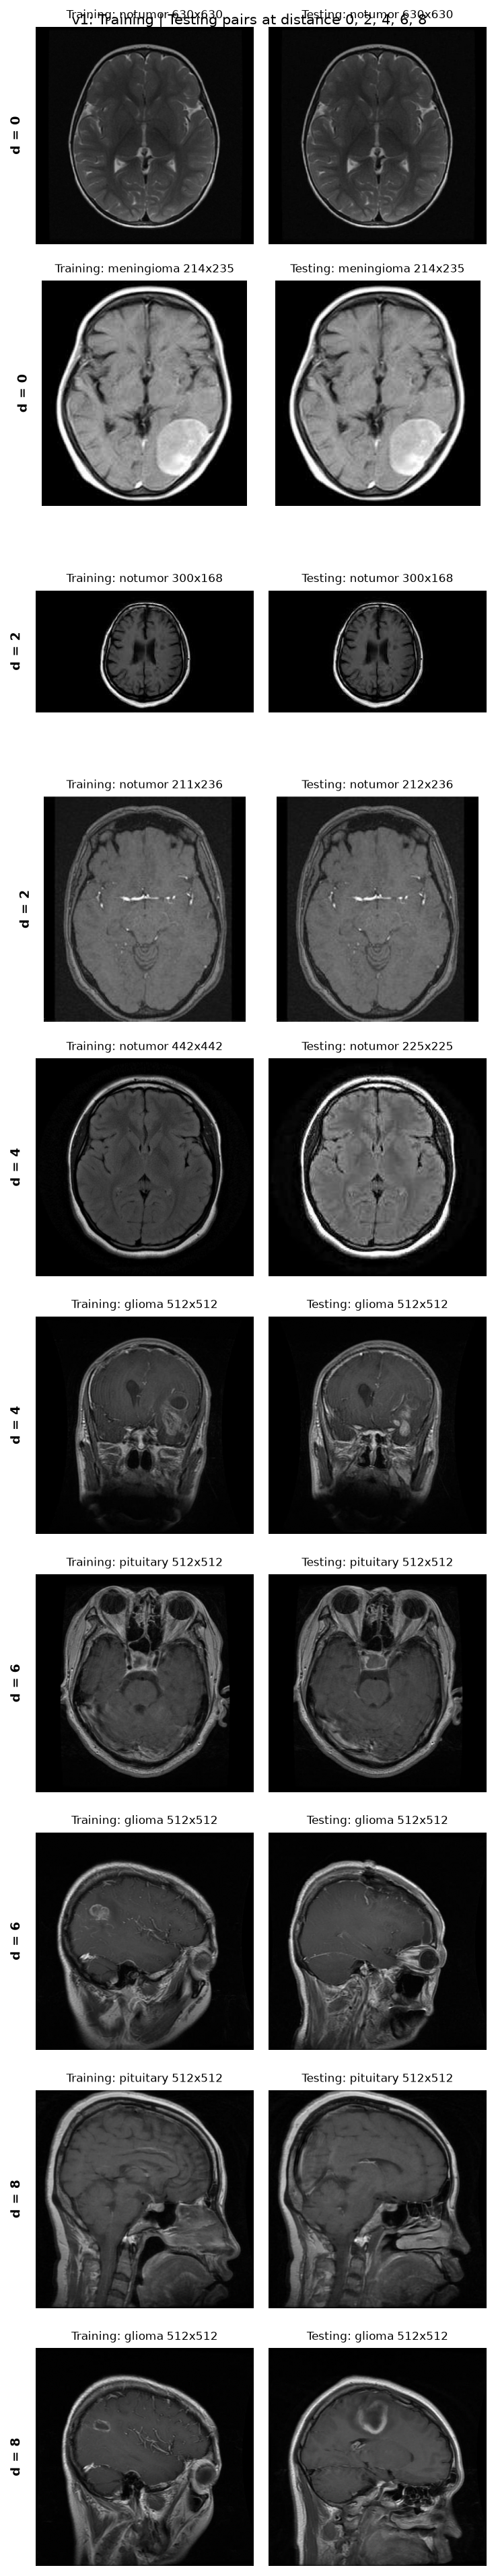

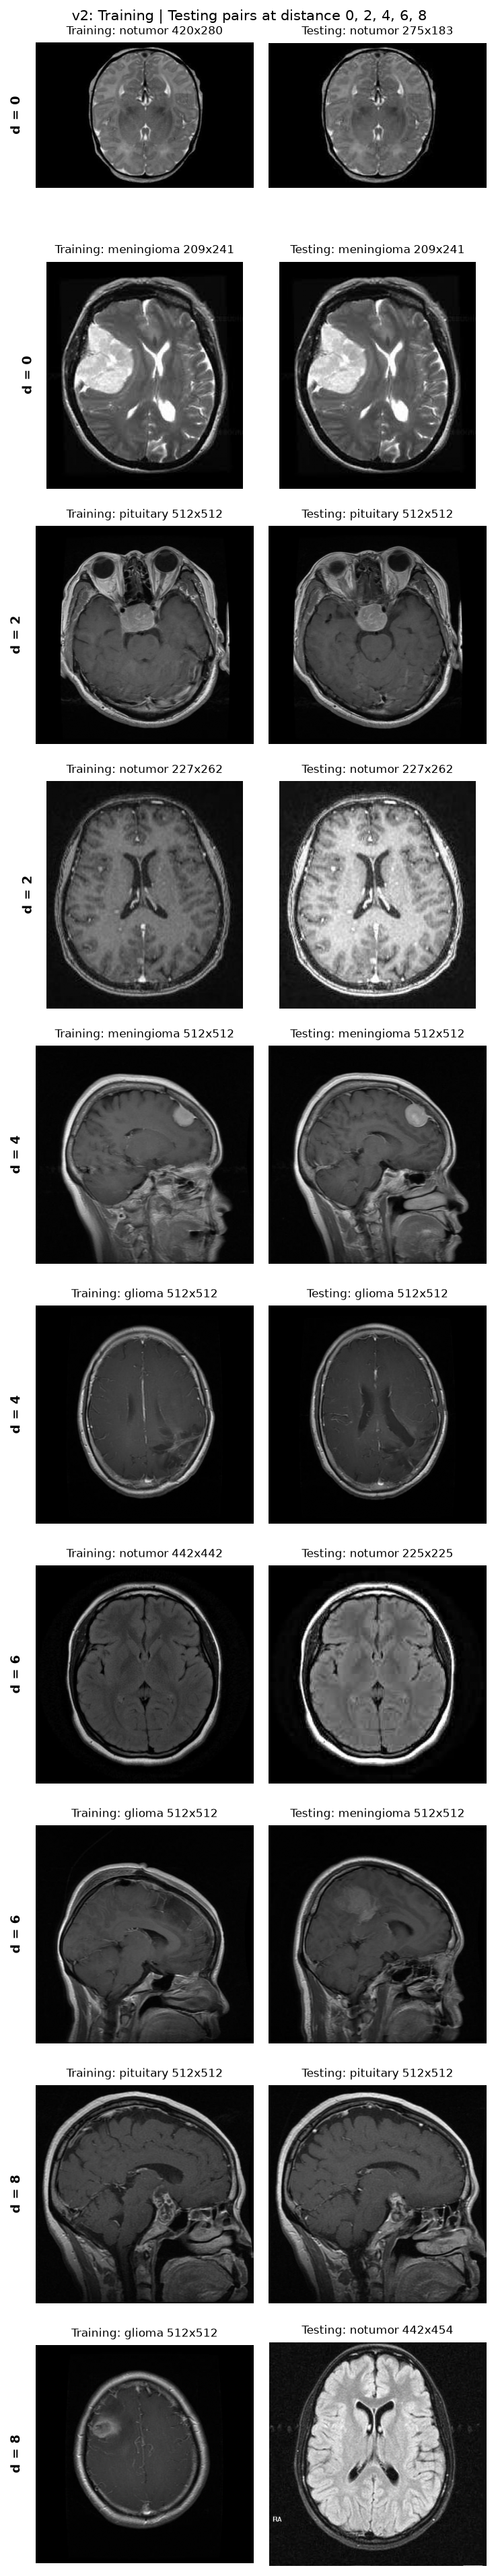

In [12]:
for v in VERSIONS:
    display(ShowImage(filename=str(a.plot_examples_by_distance(pairs[v], OUT[v], v))))

## 9. Visual check of the notumor twins
notumor has by far the highest twin rate, so we look at random notumor pairs that are *not* byte-identical.

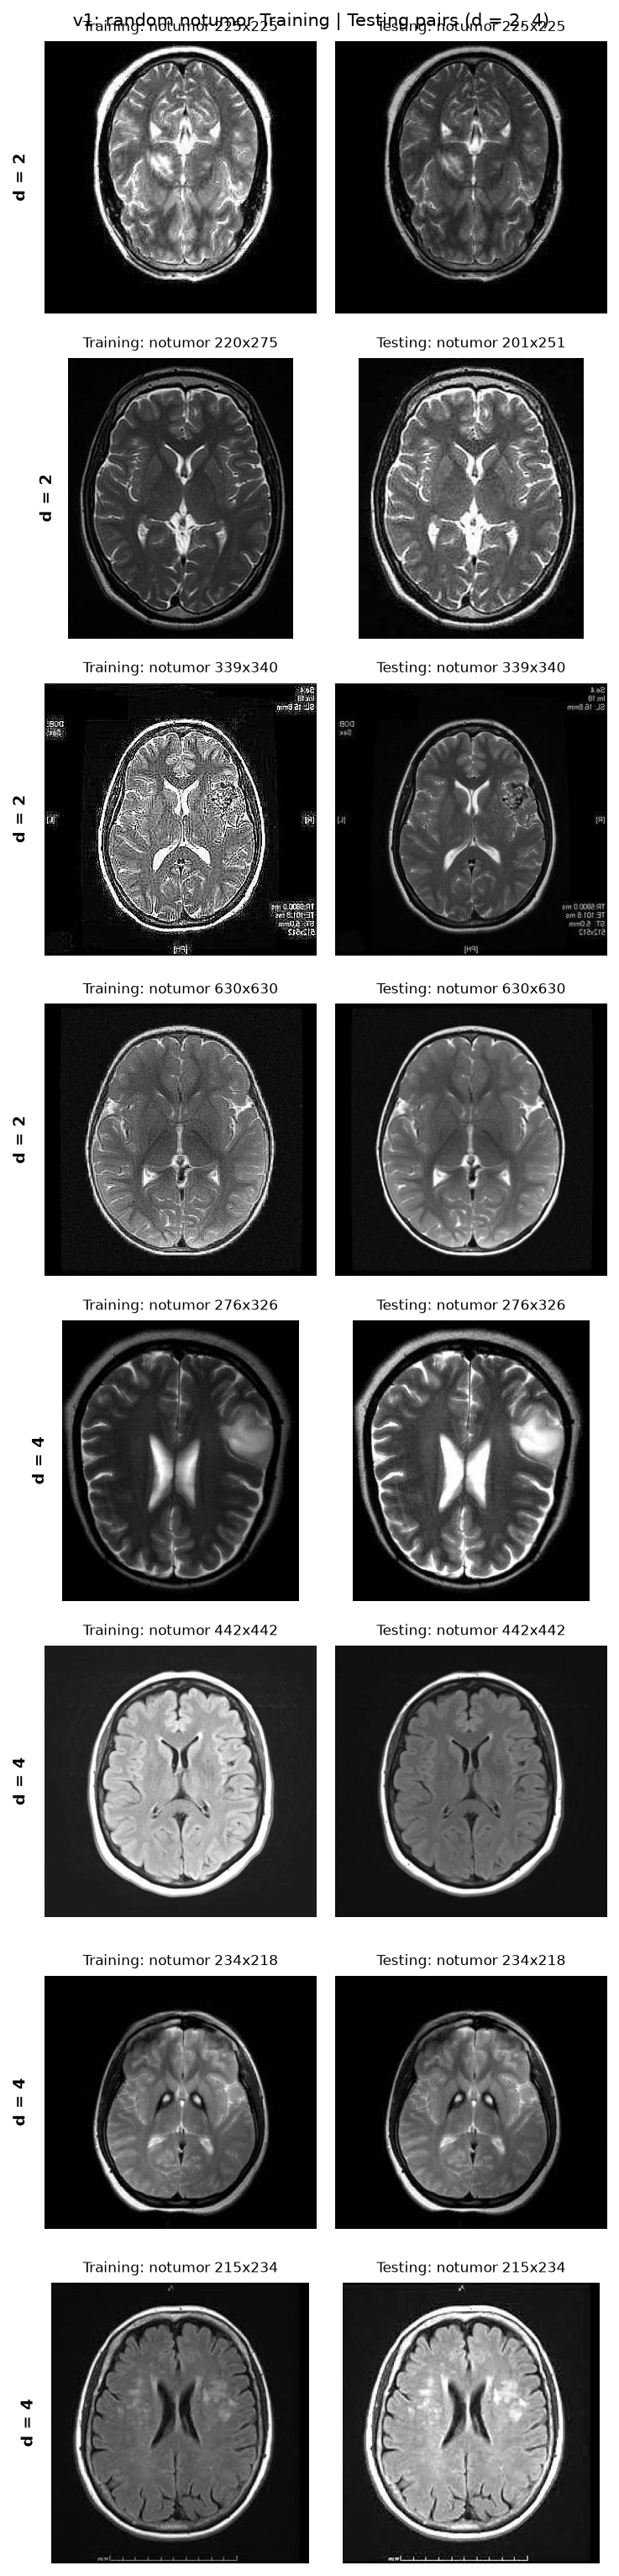

In [13]:
display(ShowImage(filename=str(a.plot_class_pairs(pairs['v1'], OUT['v1'], 'v1', 'notumor'))))

## What we found (Week 3 summary)

**1. Hashing and the GPU step worked correctly.**
- The GPU distances matched imagehash exactly on 1,000 random pairs per version (0 mismatches).
- The exact-pair count equals the count computed directly from the MD5 groups (v1 503 = 503, v2 227 = 227).
- All 24.7 M (v1) and 25.9 M (v2) pairs were compared using 143 MB of GPU memory.
- v2 took 0.065 s. The v1 time (3.45 s) includes the one-time CUDA start-up.

**2. Exact copies (MD5):**
- v1 has 7,023 files but only 6,726 distinct MD5s, giving **503 exact pairs**.
- v2 has 7,200 files and 7,013 distinct MD5s, giving **227 exact pairs**.

**3. How the threshold changes the counts:**

| | v1 T=3 | v1 T=5 | v1 T=8 | v2 T=3 | v2 T=5 | v2 T=8 |
|---|---|---|---|---|---|---|
| near pairs (not exact) | 3,973 | 6,031 | 14,654 | 3,658 | 5,666 | 14,626 |
| train-test pairs | 1,652 | 2,277 | 4,699 | 1,380 | 2,027 | 4,740 |
| label-conflict pairs | 2 | 33 | 1,850 | 11 | 47 | 1,992 |
| **test images with a Training twin** | 547 (41.7%) | **724 (55.2%)** | 1,145 (87.3%) | 505 (31.6%) | **714 (44.6%)** | 1,248 (78.0%) |

**4. Test images with a Training twin at T = 5, per class:**

| class | v1 | v2 |
|---|---|---|
| glioma | 68 / 300 (22.7%) | 86 / 400 (21.5%) |
| meningioma | 157 / 306 (51.3%) | 173 / 400 (43.3%) |
| notumor | **385 / 405 (95.1%)** | **353 / 400 (88.3%)** |
| pituitary | 114 / 300 (38.0%) | 102 / 400 (25.5%) |

**5. Duplicate groups (T = 5):**
- v1: 7,023 images form 4,516 groups. 1,072 groups have 2 or more images, and 542 groups span Training and Testing.
- v2: 7,200 images form 4,755 groups. 1,103 groups have 2 or more images, and 520 groups span Training and Testing.
- The largest group has 28 images. A group can grow like a chain (A is close to B, and B is close to C), so these groups are what the leakage-free split will keep together.

### Why we choose T = 5
- **Only even distances exist.** Every pHash has exactly 32 one-bits, so T = 3 gives the same result as T = 2, and T = 5 the same as T = 4.
- **The histogram has a valley at d = 4.** v1 train-test pair counts go 945 (d = 0), 707 (2), **625 (4)**, then rise to 842 (6), 1,580 (8) and 4,599 (10).
  - The falling part is genuine copies.
  - The rising part is the large pool of different scans that just look alike.
  - T = 5 stops at the bottom of the valley.
- **The pictures agree.**
  - At d ≤ 4 the pairs are the same picture: re-saved, resized, or with changed brightness or contrast. This holds for all 8 random notumor pairs at d = 2 and d = 4.
  - At d = 6 we start to see different slices.
  - At d = 8 the pairs are clearly different images.
- **Label conflicts stay small up to T = 5** (33 in v1, 47 in v2), but jump at T = 8 (1,850 and 1,992). At T = 8, pHash is mostly matching different scans that only look alike, not copies.
- T = 3 is too strict: it misses the d = 4 copies, which our examples show are the same image with changed contrast.

### What this means for the project
- **Most of the original test set is leaked.** At T = 5, 55.2% of v1 test images and 44.6% of v2 test images have a near copy in Training.
- Even the "cleaned" v2 is affected. Any accuracy reported on the original split is therefore partly memory, not generalisation.
- **notumor is almost entirely duplicated** (95.1% in v1). Together with the Week 1 source-bias finding, notumor accuracy on the original split is especially untrustworthy.
- The **label-conflict pairs** (in v1, 18 of the 33 are glioma-meningioma pairs inside Training) are either the same image filed under two classes or pHash look-alikes. We will check them by eye before building the clean split.
- `groups_T5.csv` gives each image a group id. The leakage-free split will put whole groups in one split.
- Not done yet: deep-feature look-alikes (CNN embeddings) to catch same-patient neighbouring slices, which pHash cannot see.